# 09 · Stress periods, parameter stability, the level of the correction, and the published Gains

**In the story** (notebook 00): this notebook supports four parts of it.
- **§4.2:** sell-offs gain significantly in 2011, 2015–2016 and February 2018, and September–December 2022 loses significantly (−0.52 for calls, −0.56 for puts).
- **§4.4:** the level of the correction supplies the Gain, the shape across strikes adds only −0.014 to +0.015 a year, and the level drifts.
- **§4.5:** our Gains beside Hull and White's published ones.
- **§5:** why the Gain fell in 2022–2023, and what it would take for the rule to lose.

The brief's model-validation direction asks to "stress-test assumptions" and "study parameter stability". This notebook collects the analyses of plan §16.9–§16.10, all descriptive and post hoc:
- **stress episodes 2011–2023,** defined from the S&P 500 close alone;
- **parameter stability** at every monthly refit, with session-clustered standard errors;
- **the maturity assumption** (1/√τ), tested by year;
- **the split of the Gain into the correction's level and its shape;**
- **our Gains under the published aggregations.**

In [1]:
import sys, json
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
R = ROOT / "results"
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.figsize": (9, 4), "axes.grid": True, "grid.alpha": 0.3})

## Stress episodes (SPX, out-of-sample, 12-month window)

In [2]:
E = pd.read_csv(R / "walkforward/stress_episodes.csv"); E

,definition,start,end,sessions,peak_rv20,index_change
0,RV,2010-05-10,2010-06-29,36,0.331021,-0.102170
1,RV,2011-08-08,2011-12-22,97,0.506576,0.120183
2,RV,2015-08-26,2015-09-23,20,0.324636,-0.000902
3,RV,2018-02-12,2018-03-05,15,0.271880,0.024450
4,RV,2018-12-26,2019-01-23,19,0.309765,0.069295
5,RV,2020-02-27,2020-05-21,60,0.978970,-0.010155
6,RV,2020-06-11,2020-07-09,20,0.311906,0.049948
7,RV,2020-09-28,2020-09-30,3,0.252434,0.003401
8,RV,2022-03-09,2022-03-22,10,0.264335,0.054637
9,RV,2022-05-04,2022-07-12,47,0.351103,-0.111942


In [3]:
G = pd.read_csv(R / "walkforward/stress_gains.csv")
x = G[(G.window == 12) & (G.rule == "R2") & (G.base == "R1")]
x[["definition", "start", "end", "cp", "gain", "lo", "hi", "sessions", "share_of_year_R1_sse", "c_fit_mean", "c_post"]].round(3)

,definition,start,end,cp,gain,lo,hi,sessions,share_of_year_R1_sse,c_fit_mean,c_post
0,RV,2011-08-08,2011-12-22,C,0.215,-0.173,0.394,93,0.396,-0.225,-0.167
11,RV,2011-08-08,2011-12-22,P,0.253,0.095,0.411,93,0.481,-0.167,-0.183
22,RV,2015-08-26,2015-09-23,C,0.224,-0.353,0.438,20,0.235,-0.132,-0.131
33,RV,2015-08-26,2015-09-23,P,0.197,-0.505,0.535,20,0.135,-0.166,-0.117
44,RV,2018-02-12,2018-03-05,C,-0.024,-0.596,0.199,15,0.021,-0.223,-0.076
55,RV,2018-02-12,2018-03-05,P,0.027,-0.313,0.193,15,0.019,-0.205,-0.092
66,RV,2018-12-26,2019-01-23,C,-0.057,-0.708,0.186,19,0.092,-0.164,-0.051
77,RV,2018-12-26,2019-01-23,P,-0.306,-1.158,0.045,19,0.079,-0.208,0.021
88,RV,2020-02-27,2020-05-21,C,0.192,-0.622,0.534,60,0.798,-0.209,-0.198
99,RV,2020-02-27,2020-05-21,P,0.103,-0.659,0.499,60,0.849,-0.204,-0.163


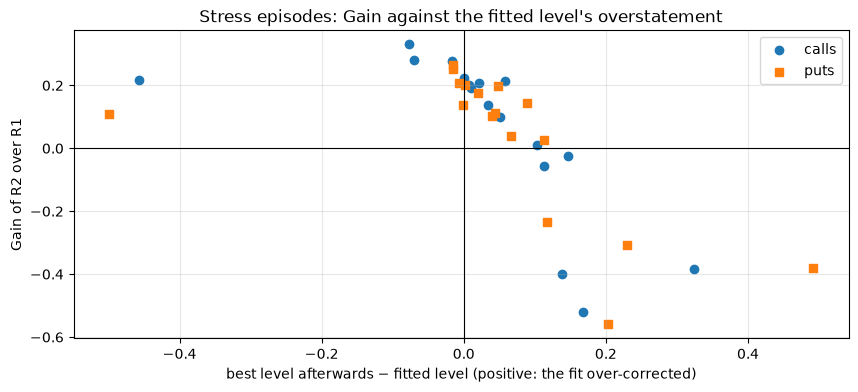

In [4]:
fig, ax = plt.subplots(figsize=(10, 4))
for cp, mk in (("C", "o"), ("P", "s")):
    z = x[x.cp == cp]
    ax.scatter(z.c_post - z.c_fit_mean, z.gain, marker=mk, label={"C": "calls", "P": "puts"}[cp])
ax.axhline(0, color="k", lw=0.8); ax.axvline(0, color="k", lw=0.8)
ax.set_xlabel("best level afterwards − fitted level (positive: the fit over-corrected)"); ax.set_ylabel("Gain of R2 over R1")
ax.set_title("Stress episodes: Gain against the fitted level's overstatement"); ax.legend()

In [5]:
Y = pd.read_csv(R / "walkforward/stress_by_year.csv")
Y[(Y.window == 12) & (Y.rule == "R2") & (Y.base == "R1")].pivot_table(index="year", columns=["regime", "cp"], values="gain").round(3)

regime RV stress          calm       
cp             C      P      C      P
year                                 
2011       0.215  0.253  0.259  0.059
2012         NaN    NaN  0.031  0.092
2013         NaN    NaN  0.151  0.155
2014         NaN    NaN  0.188  0.207
2015       0.224  0.197  0.262  0.288
2016         NaN    NaN  0.181  0.152
2017         NaN    NaN  0.124  0.052
2018       0.098 -0.032  0.027  0.064
2019      -0.292 -0.784  0.184  0.235
2020       0.189  0.104  0.166  0.223
2021         NaN    NaN  0.154  0.161
2022      -0.166 -0.161  0.127  0.052
2023         NaN    NaN  0.002 -0.014

**Reading.**
- **R2 gains in sell-offs:** every peak-to-trough drawdown (DD), significantly in 2011, 2015–2016 and the February 2018 drop.
- **It loses in rebounds and post-trough volatility,** significantly in September–December 2022 (−0.52 for calls, −0.56 for puts). There, implied volatility no longer rose as the index fell, and the fitted level over-corrected. Late 2018 and March 2022 lose too, without significance.
- **One more significant loss is too thin to read:** puts in the three-session RV episode at the end of September 2020. The episode bootstrap shortens its blocks for short episodes (the `block` column), but three sessions are too few for an interval to mean much.
- **Significance is pointwise,** over 17 episodes and two types, with no adjustment for multiplicity.
- **The scatter is consistent with the level mechanism, one way round.** Every losing episode lies to the right of zero, where the best level afterwards was weaker than the fitted level; but many episodes to the right still gain, because a fitted level less than twice too large still helps (the identity below).
- **By year,** 2022's stress sessions lost (−0.17 / −0.16) while its calm sessions gained (+0.13 / +0.05).
- **The stable spot–volatility assumption** therefore fails in one direction of stress, not the other.

SPY's episodes, in `results/spy/walkforward/stress_gains.csv`, show the same pattern.

## Parameter stability

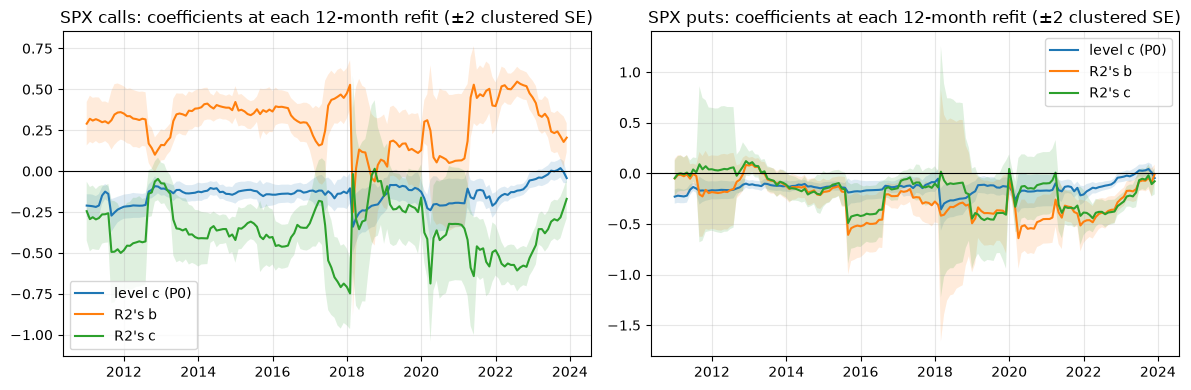

In [6]:
pp = pd.read_csv(R / "walkforward/parameter_paths.csv")
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, cp, nm in zip(axes, "CP", ("calls", "puts")):
    for rule, coef, lab in (("P0", "c0", "level c (P0)"), ("R2", "b", "R2's b"), ("R2", "c", "R2's c")):
        z = pp[(pp.window == 12) & (pp.cp == cp) & (pp.rule == rule) & (pp.coef == coef)]
        t = pd.PeriodIndex(z.month, freq="M").to_timestamp()
        ax.plot(t, z.value, label=lab); ax.fill_between(t, z.value - 2 * z.se, z.value + 2 * z.se, alpha=0.15)
    ax.axhline(0, color="k", lw=0.8); ax.set_title(f"SPX {nm}: coefficients at each 12-month refit (±2 clustered SE)"); ax.legend()
plt.tight_layout()

In [7]:
S = pd.read_csv(R / "walkforward/parameter_stability_summary.csv")
S[S.window == 12][["cp", "rule", "coef", "min", "median", "max", "median_se", "median_abs_change_over_se", "share_abs_z12_gt_2", "median_corr_bc"]].round(3)

,cp,rule,coef,min,median,max,median_se,median_abs_change_over_se,share_abs_z12_gt_2,median_corr_bc
0,C,P0,c0,-0.340,-0.135,0.018,0.033,0.229,0.188,NaN
1,C,R2,a,-0.297,-0.200,-0.006,0.033,0.243,0.132,-0.875
2,C,R2,b,-0.251,0.322,0.547,0.069,0.225,0.222,-0.875
3,C,R2,c,-0.748,-0.355,0.014,0.092,0.248,0.264,-0.875
4,C,R4,a_hat,0.799,0.924,1.005,0.017,0.238,0.229,NaN
5,P,P0,c0,-0.357,-0.138,0.043,0.038,0.230,0.097,NaN
6,P,R2,a,-0.527,-0.195,0.028,0.042,0.250,0.139,0.919
7,P,R2,b,-0.641,-0.233,0.088,0.086,0.168,0.201,0.919
8,P,R2,c,-0.491,-0.139,0.120,0.088,0.191,0.139,0.919
9,P,R4,a_hat,0.974,1.085,1.187,0.023,0.239,0.097,NaN


**Reading.**
- **R2's three coefficients are poorly identified one by one:** b and c are nearly collinear (|correlation| about 0.9), so they trade off against each other. The level they imply is well identified: P0's c, with a median standard error of about 0.03.
- **That level varies over time,** from about −0.34 to near zero. Fits 12 months apart, on non-overlapping data, differ by more than two reported standard errors in 19% of call and 10% of put comparisons (`share_abs_z12_gt_2`). These standard errors are clustered by session but omit serial dependence across sessions, so the counts somewhat overstate the instability.
- **Longer windows are smoother but staler.**
- **The fitted scaling's â** runs 0.80–1.005 for calls and 0.97–1.19 for puts; Ruf and Wang's fixed 0.9 and 1.1 sit inside both ranges.

## The maturity assumption (1/√τ), by year

In [8]:
M = pd.read_csv(R / "walkforward/maturity_by_year.csv")
M[M.regime == "all"].pivot_table(index="year", columns=["rule", "cp"], values="gain").round(3)

rule alpha:0        alpha:0.25        alpha:0.75        alpha:1       
cp         C      P          C      P          C      P       C      P
year                                                                  
2011  -0.039 -0.005      0.005  0.011     -0.048 -0.031  -0.111 -0.068
2012   0.062  0.052      0.041  0.038     -0.047 -0.045  -0.085 -0.082
2013  -0.032 -0.022     -0.005  0.003     -0.018 -0.026  -0.044 -0.058
2014  -0.058 -0.038     -0.013  0.002     -0.016 -0.030  -0.044 -0.069
2015  -0.107 -0.089     -0.033 -0.020     -0.006 -0.019  -0.033 -0.057
2016  -0.080 -0.020     -0.028  0.002      0.002 -0.018  -0.011 -0.041
2017  -0.044 -0.017     -0.014 -0.005      0.001 -0.001  -0.006 -0.004
2018  -0.066 -0.029     -0.037 -0.012      0.024  0.003   0.033 -0.000
2019  -0.096 -0.038     -0.047 -0.013      0.019 -0.006   0.014 -0.021
2020  -0.086 -0.053     -0.030 -0.019     -0.005 -0.005  -0.031 -0.024
2021  -0.070 -0.056     -0.026 -0.018     -0.003 -0.010  -0.026 -0.038
2022  -0.004  0.010     -0.002  0.002      0.001  0.004   0.001  0.012
2023  -0.003  0.009     -0.001  0.004      0.001 -0.002   0.001 -0.003

In [9]:
M[M.regime == "all"].assign(better=lambda q: q.lo > 0, worse=lambda q: q.hi < 0).groupby("rule").agg(
    better=("better", "sum"), worse=("worse", "sum"), type_years=("gain", "size"), median_gain=("gain", "median")).round(3)

,better,worse,type_years,median_gain
rule,,,,
alpha:0,1,4,26,-0.038
alpha:0.25,3,4,26,-0.009
alpha:0.75,2,8,26,-0.005
alpha:1,1,11,26,-0.029


**Reading.** No alternative exponent beats 1/√τ consistently, in any year or regime. α = 0.25 is significantly better in 3 of 26 type-years and worse in 4; α = 0.75 and α = 1 are significantly worse in 8 and 11, and every alternative has a negative median Gain against 1/√τ.

## The level and the shape of the correction

In [10]:
L = pd.read_csv(R / "walkforward/level_shape_by_year.csv")
L[["year", "cp", "c_fit", "c_post", "G_level_P0_R1", "G_shape_R2_P0", "G_R2_R1", "G_ceiling_P0post_R1", "vol_points_per_1pct_fall"]].round(3)

,year,cp,c_fit,c_post,G_level_P0_R1,G_shape_R2_P0,G_R2_R1,G_ceiling_P0post_R1,vol_points_per_1pct_fall
0,2011,C,-0.214,-0.159,0.244,-0.003,0.242,0.414,0.446
1,2011,P,-0.172,-0.169,0.152,0.000,0.152,0.168,0.446
2,2012,C,-0.210,-0.119,0.037,-0.006,0.031,0.189,0.247
3,2012,P,-0.164,-0.114,0.102,-0.012,0.092,0.175,0.247
4,2013,C,-0.125,-0.121,0.152,-0.001,0.151,0.266,0.353
5,2013,P,-0.118,-0.099,0.155,-0.001,0.155,0.257,0.353
6,2014,C,-0.126,-0.126,0.185,0.003,0.188,0.232,0.329
7,2014,P,-0.126,-0.133,0.207,0.001,0.207,0.258,0.329
8,2015,C,-0.124,-0.128,0.252,0.002,0.253,0.309,0.387
9,2015,P,-0.140,-0.143,0.271,0.006,0.276,0.341,0.387


**What the level means.** The constant correction's hedge is δ + c·ν/(S√τ), so it assumes implied volatility responds to the index as ∂σ/∂S = c/(S√τ). A 1% index fall then raises implied volatility by −c/√τ volatility points: a level of −0.13 means 0.13 vol points at one year to expiry, or 0.26 at three months.

**Reading.** In the table, `c_fit` is the fitted level (the trailing 12-month constant, averaged over the year's refits) and `c_post` the best constant for the year's own pairs, after the fact. `G_level_P0_R1` is the constant's Gain over Black–Scholes, `G_shape_R2_P0` what R2's quadratic shape adds, and `G_ceiling_P0post_R1` the Gain the best constant would have given.
- **The level of R2's correction equals P0's constant exactly.** Averaged over the training pairs with the regression's weights, R2's fitted quadratic is c: that is the first normal equation of R2's least-squares fit, since its regressors include the constant term.
- **The level supplies the Gain;** the shape adds only −0.014 to +0.015 a year on SPX.
- **A mis-estimated level costs quadratically.** Write y for a pair's Black–Scholes error and x = ν·ΔS/(S²√τ) for the regressor. A constant c leaves squared error Σy² − 2cΣxy + c²Σx², minimized at c* = Σxy/Σx². Dividing by Σy² gives the Gain exactly:

  G(c) = G* · [1 − ((c − c*)/c*)²],  where G* = (Σxy)²/(Σx²·Σy²) is the ceiling.

  So a level twice too large gains nothing, and more than that loses to Black–Scholes. In market terms: the rule loses once the spot–volatility relation weakens by more than half between the fitting window and the hedging month. The identity holds for each monthly fit and its own test month, where c is a single number; the yearly columns above average twelve fits and do not satisfy it. The next cell checks it month by month.
- **In 2023 even the ceiling was small** (0.04 for calls, 0.11 for puts, against 0.17–0.41 in 2011–2021): there was little relation left to hedge.

In [11]:
lm = pd.read_csv(R / "walkforward/level_shape_by_month.csv")
G_c, G_star, ratio = 1 - lm.sse_P0 / lm.sse_R1, 1 - lm.sse_P0_post / lm.sse_R1, lm.c_fit / lm.c_post
print(f"{len(lm)} monthly fits; largest deviation from the identity: {(G_c - G_star * (1 - (1 - ratio) ** 2)).abs().max():.1e}")
print(f"months with the fitted level more than 2x the best: {(ratio > 2).sum()}, all of which lost: {((ratio > 2) & (G_c < 0)).sum()}")
print(f"losing months: {(G_c < 0).sum()}; of these, fitted level more than 2x the best or of the wrong sign: {((G_c < 0) & ((ratio > 2) | (ratio < 0))).sum()}")

312 monthly fits; largest deviation from the identity: 7.0e-13
months with the fitted level more than 2x the best: 56, all of which lost: 56
losing months: 112; of these, fitted level more than 2x the best or of the wrong sign: 112


## Our Gains under the published aggregations

In [12]:
P = pd.read_csv(R / "walkforward/published_comparison.csv")
P[P.rule == "R2"].pivot_table(index=["window", "period", "sample"], columns="cp", values=["pooled", "mean_of_monthly"]).round(3)

mean_of_monthly        pooled       
cp                                                                         C      P      C      P
window period                          sample                                                    
12     2011-2019                       analysis (E7)                   0.039  0.009  0.119  0.112
                                       no volume rule                  0.002  0.074  0.062  0.135
                                       out of the money (E7)           0.060 -0.022  0.130  0.132
       HW overlap                      analysis (E7)                   0.095  0.100  0.211  0.195
                                       no volume rule                  0.073  0.157  0.152  0.207
                                       out of the money (E7)           0.133  0.097  0.254  0.248
       RW overlap (2012-07 to 2019-06) analysis (E7)                   0.017 -0.034  0.082  0.084
                                       no volume rule                 -0.017  0.040  0.034  0.114
                                       out of the money (E7)           0.030 -0.081  0.076  0.093
36     2011-2019                       analysis (E7)                   0.061  0.004  0.158  0.188
                                       no volume rule                  0.041  0.060  0.128  0.202
                                       out of the money (E7)           0.070 -0.024  0.164  0.218
       HW overlap                      analysis (E7)                   0.101  0.094  0.221  0.249
                                       no volume rule                  0.080  0.153  0.183  0.271
                                       out of the money (E7)           0.131  0.076  0.242  0.261
       RW overlap (2012-07 to 2019-06) analysis (E7)                   0.053 -0.016  0.143  0.170
                                       no volume rule                  0.035  0.046  0.117  0.185
                                       out of the money (E7)           0.060 -0.049  0.146  0.198

**Reading.**
- **On Hull and White's own years.** Our pooled 2013–2015 Gains with 36-month fits are 0.22 / 0.25, while Hull and White report mean monthly Gains of 0.26 / 0.23 over 2007–2015.
- **Their monthly averaging makes our Gains look lower, not higher.** Our mean of monthly Gains on 2013–2015 is 0.10 / 0.09. Their 2007–2012 is not in our data, so the comparison is of different periods.
- **Against Ruf and Wang** (their period, mid-2012 to mid-2019, out of the money, 36-month fits), our puts gain 0.20 against their 0.17, and our calls fall short (0.15 against 0.23).
- **Our lower headline** reflects the period (2017, 2018 and 2022–2023 are weak years), the 12-month window (pooled over mid-2012 to mid-2019, about half the 36-month Gain: 0.08 against 0.14–0.17), and in-the-money calls (about half our call sample; notebook 01). The last is the smallest of the three: restricting to out-of-the-money options raises the pooled 2011–2019 Gain only from 0.119 to 0.130 (calls) and 0.112 to 0.132 (puts). These are readings of the table, not a decomposition.
- **The volume rule is not the main cause:** dropping it (`no volume rule`) moves our pooled Gains by 0.01–0.06, in opposite directions for calls and puts.